# Customer Churn Prediction Using Machine Learning

## 1. Introduction
Customer churn refers to the situation where customers stop using a company's products or services. The goal of this project is to predict whether a customer is likely to leave a telecom company using historical customer data.


## 2. Importing Libraries and Loading the Dataset

In [35]:
!pip uninstall watson-machine-learning-client -y
!pip install --user watson-machine-learning-client-v4==1.0.103 --upgrade | tail -n 1
!pip install --user pyspark==2.3.3 --upgrade|tail -n 1
!pip install --user scikit-learn==0.20.3 --upgrade|tail -n 1

ERROR: Can not perform a '--user' install. User site-packages are not visible in this virtualenv.
ERROR: Can not perform a '--user' install. User site-packages are not visible in this virtualenv.
ERROR: Can not perform a '--user' install. User site-packages are not visible in this virtualenv.


## 2.0 Load and Clean data

We'll load our data as a pandas data frame.



In [36]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [37]:
# Search the current folder and its parent folders
current_dir = Path.cwd()

matches = list(current_dir.glob("**/Telco-Customer-Churn.csv"))

if not matches:
    matches = list(current_dir.parent.glob("**/Telco-Customer-Churn.csv"))

if not matches:
    raise FileNotFoundError(
        "Dataset not found. Please check the data folder."
    )

# Use the first matching dataset
DATA_PATH = matches[0]

print("Dataset found at:", DATA_PATH.resolve())

# Load dataset
df = pd.read_csv(DATA_PATH)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset found at: /media/anurag/Personals/Mansi/AI Practice Projects/customer-churn-prediction/telco-customer-churn-on-icp4d-master/data/Telco-Customer-Churn.csv

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


We'll use the Pandas naming convention df for our DataFrame. Make sure that the cell below uses the name for the dataframe used above. For the locally uploaded file it should look like df_data_1 or df_data_2 or df_data_x. For the virtualized data case it should look like data_df_1 or data_df_2 or data_df_x.

**<font color='red'><< UPDATE THE VARIABLE ASSIGNMENT TO THE VARIABLE GENERATED ABOVE. >></font>**

## 2.1 Understanding the Dataset

Each row in the dataset represents an individual customer, and each column contains information about that customer, such as tenure, contract type, monthly charges, and payment method.

The `Churn` column is our target variable, which indicates whether a customer has left the company.

In [38]:
display(df.info())
display(df.describe(include="all").T)
print("\\nMissing values by column:")
display(df.isna().sum().sort_values(ascending=False))

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\nMissing values by column:


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

### 3.1 Data Cleaning and Target Preparation

- Validate the `Churn` target column.
- Convert `TotalCharges` to numeric format.
- Remove duplicate rows and the `customerID` identifier.
- Normalize churn labels and remove invalid target values.
- Encode `No` as `0` and `Yes` as `1`.
- Display the cleaned dataset shape and churn distribution.

**Objective:** Prepare clean, consistent data for machine learning.

In [39]:
if "Churn" not in df.columns:
    raise ValueError("The dataset must contain a 'Churn' target column.")

# Convert TotalCharges if present; blank strings become NaN.
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Remove duplicate rows if any.
before = len(df)
df = df.drop_duplicates().copy()
print(f"Duplicate rows removed: {before - len(df)}")

# Drop the identifier only if it exists.
df = df.drop(columns=["customerID"], errors="ignore")

# Normalize target values and keep rows with known target.
df["Churn"] = df["Churn"].astype("string").str.strip()
df = df[df["Churn"].isin(["Yes", "No"])].copy()
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1}).astype(int)

print("Cleaned dataset shape:", df.shape)
print("Target counts (0 = No churn, 1 = Churn):")
display(df["Churn"].value_counts().rename(index={0: "No churn", 1: "Churn"}))

Duplicate rows removed: 0
Cleaned dataset shape: (7043, 20)
Target counts (0 = No churn, 1 = Churn):


Churn
No churn    5174
Churn       1869
Name: count, dtype: int64

### 4.1 Customer Churn Distribution

- Visualize the number of customers who churned and those who stayed.
- Calculate the overall churn rate.
- Identify the imbalance between churn and non-churn customers.

**Objective:** Understand the distribution of the target variable.

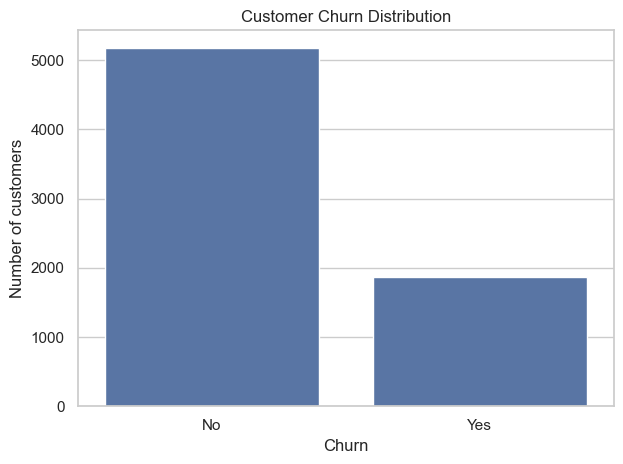

Churn rate: 26.54%


In [40]:
churn_counts = df["Churn"].map({0: "No", 1: "Yes"}).value_counts()
ax = sns.barplot(x=churn_counts.index, y=churn_counts.values)
ax.set(title="Customer Churn Distribution", xlabel="Churn", ylabel="Number of customers")
plt.tight_layout()
plt.show()

print("Churn rate: {:.2%}".format(df["Churn"].mean()))

### 5.1 Feature Selection and Train-Test Split

- Separate input features (`X`) from the target variable (`y`).
- Identify numerical and categorical features.
- Split the data into 80% training and 20% testing sets.
- Use stratification to preserve the churn distribution in both sets.

**Objective:** Prepare data for model training and unbiased evaluation.

In [41]:
X = df.drop(columns="Churn")
y = df["Churn"]

# Numeric and categorical columns are detected from the feature data.
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Training rows: 5634
Test rows: 1409


### 5.2 Data Preprocessing and Model Training

- Handle missing numerical and categorical values using imputation.
- Scale numerical features using `StandardScaler`.
- Convert categorical features into numerical format using `OneHotEncoder`.
- Combine preprocessing and a Random Forest classifier into a single pipeline.
- Train the model using the training dataset.

**Objective:** Prepare features and train a model to predict customer churn.

In [42]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        min_samples_leaf=2
    ))
])

model.fit(X_train, y_train)
print("Model training complete.")

Model training complete.


### 5.3 Model Evaluation

- Generate churn predictions and predicted probabilities on the test dataset.
- Evaluate performance using Accuracy, Precision, Recall, F1-score, and ROC-AUC.
- Display the classification report for both churn and non-churn customers.

**Objective:** Assess how effectively the model predicts customer churn on unseen data.

In [43]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1-score : {f1_score(y_test, y_pred, zero_division=0):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_proba):.3f}")
print("\\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["No churn", "Churn"], zero_division=0))

Accuracy : 0.784
Precision: 0.585
Recall   : 0.647
F1-score : 0.614
ROC-AUC  : 0.835
\nClassification report:
              precision    recall  f1-score   support

    No churn       0.87      0.83      0.85      1035
       Churn       0.58      0.65      0.61       374

    accuracy                           0.78      1409
   macro avg       0.73      0.74      0.73      1409
weighted avg       0.79      0.78      0.79      1409



### 5.4 Confusion Matrix

- Visualize the model's correct and incorrect predictions.
- Identify true positives, true negatives, false positives, and false negatives.

**Objective:** Understand the types of prediction errors made by the model.

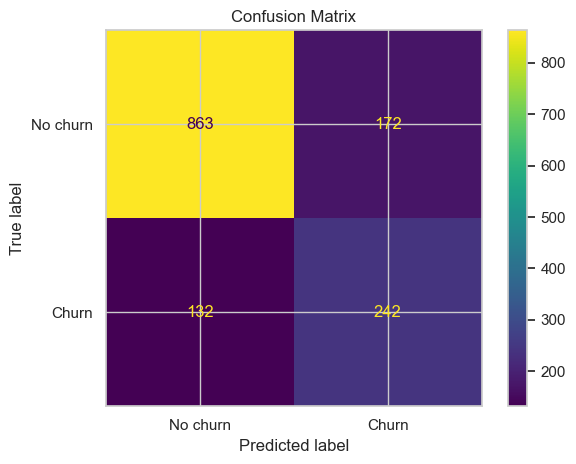

In [44]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No churn", "Churn"])
disp.plot(values_format="d")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

### 5.5 Customer Churn Prediction

- Select a sample customer from the test dataset.
- Predict the probability of customer churn.
- Display the prediction as **Likely to churn** or **Likely to stay**.

**Objective:** Demonstrate how the trained model predicts churn for an individual customer.

In [45]:
sample_customer = X_test.iloc[[0]]
probability = model.predict_proba(sample_customer)[0, 1]
prediction = model.predict(sample_customer)[0]

display(sample_customer)
print(f"Predicted churn probability: {probability:.1%}")
print("Prediction:", "Likely to churn" if prediction == 1 else "Likely to stay")

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2


Predicted churn probability: 0.6%
Prediction: Likely to stay


### 5.6 Saving the Trained Model

- Save the trained machine learning pipeline using `joblib`.
- Store the model as `churn_model.joblib` for future use without retraining.

**Objective:** Reuse the trained model to predict customer churn on new data.

In [46]:
MODEL_PATH = Path("churn_model.joblib")
joblib.dump(model, MODEL_PATH)
print(f"Saved model to: {MODEL_PATH.resolve()}")

Saved model to: /media/anurag/Personals/Mansi/AI Practice Projects/customer-churn-prediction/telco-customer-churn-on-icp4d-master/notebooks/churn_model.joblib


### 5.7 Loading and Verifying the Saved Model

- Load the saved model using `joblib`.
- Generate a churn prediction and probability for the sample customer.
- Verify that the loaded model produces consistent results.

**Objective:** Ensure the saved model can be reused without retraining.

In [47]:
loaded_model = joblib.load(MODEL_PATH)

# Example: use the same sample row to verify that the saved model works.
loaded_prediction = loaded_model.predict(sample_customer)[0]
loaded_probability = loaded_model.predict_proba(sample_customer)[0, 1]

print("Loaded model prediction:", "Likely to churn" if loaded_prediction == 1 else "Likely to stay")
print(f"Loaded model churn probability: {loaded_probability:.1%}")

Loaded model prediction: Likely to stay
Loaded model churn probability: 0.6%
